# Project Two Pirate Intelligent Agent
**Sean McKenna | CS 370**

This notebook trains a pirate to reach the treasure in the supplied 8 × 8 maze using deep Q-learning. The final evaluation checks the greedy policy from every nonterminal free cell and demonstrates the required top-left start. The supplied Python modules remain unchanged.


## Environment and replay memory
`TreasureMaze.py` supplies the maze, actions, rewards, and game status. `GameExperience.py` stores individual transitions and constructs mini-batch learning targets. The completed training loop below connects these classes to the supplied neural network.


<div class="alert alert-block alert-warning" style="color: #333333;">
<b>Installations</b> The following command will install the necessary Python libraries to necessary to run this application. If you see a "[notice] A new release of pip is available: 23.1.2 -> 25.2" at the end of the installation, you may disregard that statement. 
</div>

In [1]:
%pip install -r requirements.txt

<h2>Tensorflow CPU Acceleration Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
    <b>Example messages:</b>
    <ul>
        <li>oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders</li>
        <li>WARNING: All log messages before absl::InitializeLog() is called are written to STDERR</li>
</div>

In [2]:
from __future__ import print_function
import os, sys, time, datetime, json, random
import numpy as np
# Use the CPU to avoid shared Codio GPU memory limits.
os.environ["CUDA_VISIBLE_DEVICES"] = "-1"
import tensorflow as tf
from tensorflow.keras.models import clone_model
from keras.models import Sequential
from keras.layers import Dense, Activation, PReLU
from keras.optimizers import SGD , Adam, RMSprop
import matplotlib.pyplot as plt
from TreasureMaze import TreasureMaze
from GameExperience import GameExperience
%matplotlib inline

Matplotlib is building the font cache; this may take a moment.


<h2> Maze Object Generation</h2>

<div class="alert alert-block alert-info" style="color:black;">
    <b>NOTE:</b>  The following code block contains an 8x8 matrix that will be used as a maze object:
</div>

In [3]:
maze = np.array([
    [ 1.,  0.,  1.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  0.,  1.,  1.,  1.,  0.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  0.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  0.,  1.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  0.,  1.,  0.,  0.,  0.],
    [ 1.,  1.,  1.,  0.,  1.,  1.,  1.,  1.],
    [ 1.,  1.,  1.,  1.,  0.,  1.,  1.,  1.]
])

<h2>Helper Functions and Global Variables</h2>

<div class="alert alert-block alert-info" style="color:black;">
This <b>show()</b> helper function allows a visual representation of the maze object:
</div>

In [4]:
def show(qmaze):
    plt.grid('on')
    nrows, ncols = qmaze.maze.shape
    ax = plt.gca()
    ax.set_xticks(np.arange(0.5, nrows, 1))
    ax.set_yticks(np.arange(0.5, ncols, 1))
    ax.set_xticklabels([])
    ax.set_yticklabels([])
    canvas = np.copy(qmaze.maze)
    for row,col in qmaze.visited:
        canvas[row,col] = 0.6
    pirate_row, pirate_col, _ = qmaze.state
    canvas[pirate_row, pirate_col] = 0.3   # pirate cell
    canvas[nrows-1, ncols-1] = 0.9 # treasure cell
    img = plt.imshow(canvas, interpolation='none', cmap='gray')
    return img

The pirate can move left, up, right, or down. **Exploration** samples a valid action; **exploitation** selects the action with the largest predicted Q-value. Learning occurs from transitions collected under both choices. Epsilon is the probability of choosing the exploration branch.


In [5]:
LEFT = 0
UP = 1
RIGHT = 2
DOWN = 3


# Exploration factor
epsilon = 1.0
epsilon_min = 0.05
epsilon_decay = 0.995

# Actions dictionary
actions_dict = {
    LEFT: 'left',
    UP: 'up',
    RIGHT: 'right',
    DOWN: 'down',
}

num_actions = len(actions_dict)


The sample code block and output below show creating a maze object and performing one action (DOWN), which returns the reward. The resulting updated environment is visualized.

reward= -0.04


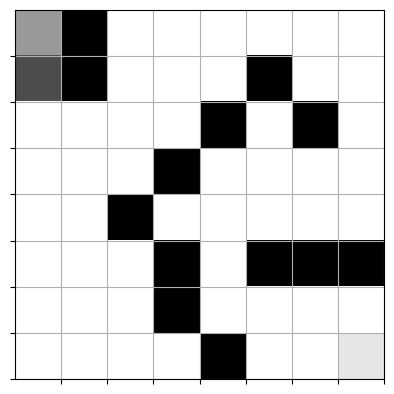

In [6]:
qmaze = TreasureMaze(maze)
canvas, reward, game_over = qmaze.act(DOWN)
print("reward=", reward)
show(qmaze)

<div class="alert alert-block alert-warning" style="color:black;">
    <b>NOTE:</b> This <b>play_game()</b> function simulates a full game based on the provided trained model. The other parameters include the TreasureMaze object, the starting position of the pirate and max amount of steps to make sure the code does not get stuck in a loop.
</div>

In [7]:
def play_game(model, qmaze, pirate_cell, max_steps=None):
    qmaze.reset(pirate_cell)
    envstate = qmaze.observe()
    steps = 0
    if max_steps is None:
        max_steps = qmaze.maze.size * 4  # safety cutoff

    while steps < max_steps:
        state = np.asarray(envstate, dtype=np.float32)
        if state.ndim == 1:
            state = np.expand_dims(state, axis=0)

        q_values = model(state, training=False).numpy()
        action = np.argmax(q_values[0])

        envstate, reward, game_status = qmaze.act(action)
        steps += 1

        if game_status == 'win':
            return True
        elif game_status == 'lose':
            return False

    return False  # timed out with no result

`completion_check()` evaluates the greedy policy from every nonterminal free starting cell in this maze. A successful recent training window alone does not establish this broader coverage.


In [8]:
def completion_check(model, maze_or_qmaze, max_steps=None):
    # Accept either raw numpy maze or TreasureMaze instance
    if isinstance(maze_or_qmaze, TreasureMaze):
        qmaze = maze_or_qmaze
    else:
        qmaze = TreasureMaze(maze_or_qmaze)

    for cell in qmaze.free_cells:
        if not qmaze.valid_actions(cell):
            continue
        if not play_game(model, qmaze, cell, max_steps=max_steps):
            return False
    return True

<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b>
</b>The <b>build_model()</b> function in the block below will build the neural network model. Review the code and note the number of layers, as well as the activation, optimizer, and loss functions that are used to train the model.
</div>

In [9]:
def build_model(maze):
    model = Sequential()
    model.add(Dense(maze.size, input_shape=(maze.size,)))
    model.add(PReLU())
    model.add(Dense(maze.size))
    model.add(PReLU())
    model.add(Dense(num_actions))
    model.compile(optimizer='adam', loss='mse')
    return model

<div class="alert alert-block alert-warning" style="color:black;">
    <b>Note:</b>
    This <b>train_step()</b> helper function in the block below is used to help predict Q-values (quality values) in the current modelto see how good each action is in a given state and improve the Q-network by reducing the gap between what is predicted and what should have been predicted. 
</div>
<br>
<div class="alert alert-block alert-info" style="color:black;">
If you're interested in reading up on the <i>@tf.function</i>, which is a decorator for Tensorflow to run this code into a TensorFlow computation graph, please refer to this link: <a href="https://www.tensorflow.org/guide/intro_to_graphs">https://www.tensorflow.org/guide/intro_to_graphs</a>
</div>


<h2>Tensorflow GPU Warning</h2>
<div class="alert alert-block alert-danger" style="color: #333333;">
    You will see a <b>warning in red</b> "INTERNAL: CUDA Runtime error: Failed call to cudaGetRuntimeVersion: Error loading CUDA libraries. GPU will not be used.". This is simply coming from <b>Tensorflow skipping using GPU for this assignment.</b>  
</div>

In [10]:
loss_fn = tf.keras.losses.MeanSquaredError()
optimizer = tf.keras.optimizers.Adam()

@tf.function
def train_step(x, y):
    with tf.GradientTape() as tape:
        q_values = model(x, training=True)
        loss = loss_fn(y, q_values)
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))
    return loss

## Q Training Algorithm
Each epoch is one game from a random free starting cell. At each step, the agent chooses an epsilon-greedy action, receives an observation and reward, stores a transition, and updates the online network using sampled replay data. A separate target network is synchronized every 50 gradient updates.

The replay target for a nonterminal transition is `reward + 0.95 * max(target_Q(next_state))`; for a true terminal transition it is just `reward`. A Boolean terminal flag is essential because a nonempty status string would incorrectly mark every transition as terminal. A safety time limit ends a rollout without suppressing the bootstrap target for an otherwise nonterminal state.

Training stops when the latest 32 games are all wins **and** the supplied completion check succeeds. The 3,000-epoch limit is a budget, not a claim about the minimum number of epochs needed.


In [11]:
class ReplayPredictor:
    """Expose fast, batched inference through the replay class's interface."""

    def __init__(self, network):
        self.output_shape = network.output_shape
        self._predict = tf.function(
            lambda states: network(states, training=False),
            input_signature=[tf.TensorSpec(
                shape=(None, network.input_shape[-1]), dtype=tf.float32
            )]
        )

    def __call__(self, states, training=False):
        # Replay only requests inference, never training-mode predictions.
        return self._predict(tf.convert_to_tensor(states, dtype=tf.float32))


def qtrain(model, maze, **opt):
    """Train the pirate with epsilon-greedy deep Q-learning and replay."""
    global epsilon

    n_epoch = opt.get('n_epoch', 15000)
    max_memory = opt.get('max_memory', 1000)
    data_size = opt.get('data_size', 50)
    # Count target updates in gradient steps, not full games.
    target_update_freq = opt.get('target_update_freq', 50)
    max_steps = opt.get('max_steps', maze.size * 4)
    if min(n_epoch, max_memory, data_size, target_update_freq, max_steps) <= 0:
        raise ValueError("Training limits must all be positive.")

    start_time = datetime.datetime.now()
    qmaze = TreasureMaze(maze)
    target_model = clone_model(model)
    target_model.set_weights(model.get_weights())
    # Compile inference used repeatedly by the unchanged replay class.
    # The adapters share the real networks' weights; training and target
    # synchronization still operate directly on those original networks.
    experience = GameExperience(
        ReplayPredictor(model), ReplayPredictor(target_model),
        max_memory=max_memory
    )

    win_history = []
    hsize = qmaze.maze.size // 2
    win_rate = 0.0
    update_count = 0
    history = []
    solved = False

    for epoch in range(n_epoch):
        # Random starts expose the network to routes throughout the maze.
        agent_cell = random.choice(qmaze.free_cells)
        qmaze.reset(agent_cell)
        envstate = qmaze.observe()
        game_status = 'not_over'
        losses = []
        n_episodes = 0

        for step in range(max_steps):
            previous_envstate = envstate
            valid_actions = qmaze.valid_actions()
            if not valid_actions:
                raise ValueError("The pirate has no valid action from this cell.")

            # Explore legal moves; exploit the same argmax policy as play_game.
            # Greedy invalid moves receive the supplied environment's penalty.
            if np.random.random() < epsilon:
                action = random.choice(valid_actions)
            else:
                action = int(np.argmax(experience.predict(previous_envstate)))

            envstate, reward, game_status = qmaze.act(action)
            n_episodes += 1
            truncated = (step + 1 == max_steps and game_status == 'not_over')
            terminated = game_status in ('win', 'lose')
            game_over = terminated or truncated

            # Replay needs true termination, not a status string or time cutoff.
            # Terminal transitions use reward alone; others bootstrap from
            # reward + discount * max(target network's next-state Q-values).
            experience.remember([
                previous_envstate, action, reward, envstate, terminated
            ])
            inputs, targets = experience.get_data(batch_size=data_size)
            batch_loss = train_step(inputs, targets)
            losses.append(float(batch_loss.numpy()))
            update_count += 1

            # Keep targets fixed between periodic copies of the online weights.
            if update_count % target_update_freq == 0:
                target_model.set_weights(model.get_weights())
            if game_over:
                break

        # Record one result per game, including cutoffs as losses.
        win_history.append(int(game_status == 'win'))
        loss = float(np.mean(losses))
        if len(win_history) >= hsize:
            win_rate = sum(win_history[-hsize:]) / hsize
        history.append((epoch + 1, loss, n_episodes, win_rate, epsilon))

        # A full 100% window must also pass the unmodified all-start check.
        if win_rate == 1.0:
            solved = completion_check(model, maze, max_steps=max_steps)

        if epoch == 0 or (epoch + 1) % 25 == 0 or solved or epoch + 1 == n_epoch:
            elapsed = format_time((datetime.datetime.now() - start_time).total_seconds())
            print("Epoch: {:04d}/{:d} | Loss: {:.5f} | Steps: {:d} | "
                  "Wins: {:d} | Last {:d} win rate: {:.3f} | Epsilon: {:.3f} | Time: {}"
                  .format(epoch + 1, n_epoch, loss, n_episodes,
                          sum(win_history), hsize, win_rate, epsilon, elapsed))

        if solved:
            print("100% recent win rate and completion_check passed at epoch", epoch + 1)
            break
        epsilon = (epsilon_min if win_rate > 0.9
                   else max(epsilon * epsilon_decay, epsilon_min))

    if not solved:
        print("Epoch limit reached; the combined success criterion was not met.")
    total_time = format_time((datetime.datetime.now() - start_time).total_seconds())
    print("Training complete in:", total_time)
    return {'solved': solved, 'epochs': epoch + 1, 'win_rate': win_rate,
            'updates': update_count, 'history': history}


def format_time(seconds):
    """Format elapsed training time for the progress log."""
    if seconds < 400:
        return "%.1f seconds" % seconds
    if seconds < 4000:
        return "%.2f minutes" % (seconds / 60.0)
    return "%.2f hours" % (seconds / 3600.0)


## Train and Evaluate
Restart the kernel and run all cells for a fresh experiment. The next cell displays the untrained maze; the training and evaluation outputs follow.


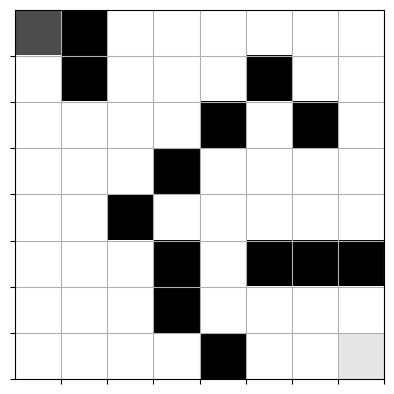

In [12]:
qmaze = TreasureMaze(maze)
show(qmaze)

In the next code block, you will build your model using the <b>build_model</b> function and train it using deep Q-learning. Note: This step takes several minutes to fully run.



The random seed is fixed at 42. Floating-point differences between TensorFlow versions and computers can change the stopping epoch, so success is checked directly after training.

In [13]:
# Set the seed before initialization; stopping time can vary by platform.
tf.keras.utils.set_random_seed(42)
epsilon = 1.0
model = build_model(maze)
training_results = qtrain(model, maze, n_epoch=3000, max_memory=64*maze.size,
                         data_size=32, target_update_freq=50)


/Users/seanmckenna/.codex/.chatgpt-projects/g-p-6a95cd76e7c881919c503ab507141e72/.assignment2-venv/lib/python3.12/site-packages/keras/src/layers/core/dense.py:92: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch: 0001/3000 | Loss: 0.00383 | Steps: 158 | Wins: 0 | Last 32 win rate: 0.000 | Epsilon: 1.000 | Time: 0.6 seconds


Epoch: 0025/3000 | Loss: 0.00741 | Steps: 34 | Wins: 7 | Last 32 win rate: 0.000 | Epsilon: 0.887 | Time: 2.9 seconds


Epoch: 0050/3000 | Loss: 0.01845 | Steps: 152 | Wins: 12 | Last 32 win rate: 0.219 | Epsilon: 0.782 | Time: 5.4 seconds


Epoch: 0075/3000 | Loss: 0.00181 | Steps: 2 | Wins: 22 | Last 32 win rate: 0.344 | Epsilon: 0.690 | Time: 7.4 seconds


...

Epoch: 0400/3000 | Loss: 0.01214 | Steps: 32 | Wins: 240 | Last 32 win rate: 0.969 | Epsilon: 0.050 | Time: 27.9 seconds


Epoch: 0425/3000 | Loss: 0.00432 | Steps: 23 | Wins: 265 | Last 32 win rate: 1.000 | Epsilon: 0.050 | Time: 35.3 seconds


Epoch: 0450/3000 | Loss: 0.00564 | Steps: 24 | Wins: 290 | Last 32 win rate: 1.000 | Epsilon: 0.050 | Time: 43.0 seconds


Epoch: 0475/3000 | Loss: 0.00622 | Steps: 9 | Wins: 315 | Last 32 win rate: 1.000 | Epsilon: 0.050 | Time: 51.7 seconds


Epoch: 0482/3000 | Loss: 0.00367 | Steps: 9 | Wins: 322 | Last 32 win rate: 1.000 | Epsilon: 0.050 | Time: 54.8 seconds
100% recent win rate and completion_check passed at epoch 482
Training complete in: 54.8 seconds


<div class="alert alert-block alert-warning" style="color:black;">
<b>Note: </b> This cell will check to see if the model passes the completion check. Note: This could take several minutes.
</div>

In [14]:
# Evaluate the frozen greedy policy from every nonterminal free cell.
all_starts_passed = completion_check(model, maze)
evaluation_maze = TreasureMaze(maze)
start_results = [play_game(model, evaluation_maze, cell)
                 for cell in evaluation_maze.free_cells]
print("Completion check:", all_starts_passed)
print("Greedy evaluation: {}/{} starts won ({:.1%}).".format(
    sum(start_results), len(start_results), np.mean(start_results)))
assert training_results['solved'], "Training did not meet the success criterion."
assert all_starts_passed and all(start_results), "Some starting cells still fail."


Completion check: True
Greedy evaluation: 50/50 starts won (100.0%).


This cell will test your model for one game. It will start the pirate at the top-left corner and run <b>play_game()</b>. The agent should find a path from the starting position to the target (treasure). The treasure is located in the bottom-right corner.

Top-left start reached treasure: True
Final position: (7, 7) | Total reward: 0.08


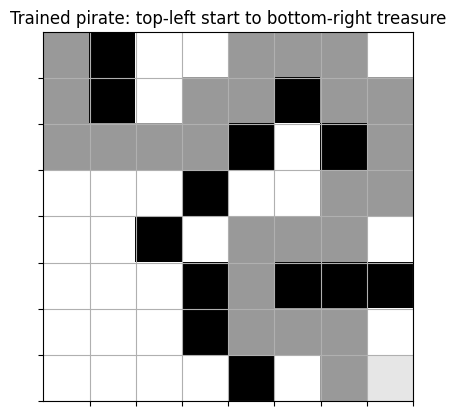

In [15]:
pirate_start = (0, 0)
won = play_game(model, qmaze, pirate_start)
print("Top-left start reached treasure:", won)
print("Final position:", qmaze.state[:2], "| Total reward:", round(qmaze.total_reward, 2))
assert won and qmaze.state[:2] == qmaze.target
show(qmaze)
plt.title("Trained pirate: top-left start to bottom-right treasure")
plt.show()


## Route and Learning Diagnostics
The following evaluation records the learned route and compares its length with a breadth-first search reference. Breadth-first search is used only after training to assess route length; it supplies no training actions, rewards, or targets.


Learned route: [(0, 0), (1, 0), (2, 0), (2, 1), (2, 2), (2, 3), (1, 3), (1, 4), (0, 4), (0, 5), (0, 6), (1, 6), (1, 7), (2, 7), (3, 7), (3, 6), (4, 6), (4, 5), (4, 4), (5, 4), (6, 4), (6, 5), (6, 6), (7, 6), (7, 7)]
Learned route steps: 24
Shortest possible route steps: 24
Excess steps: 0
Actions: down, down, right, right, right, up, right, up, right, right, down, right, down, down, left, down, left, left, down, down, right, right, down, right


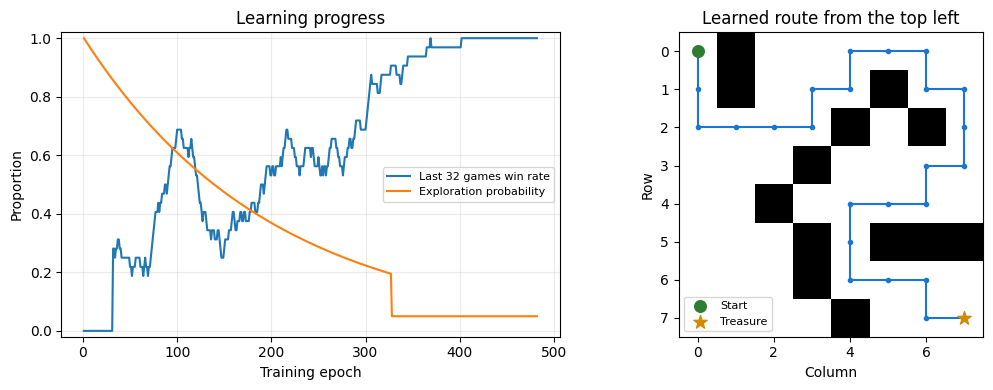

In [16]:
from collections import deque

def shortest_distance(maze_array, start, goal):
    """Return a reference distance on this unweighted grid for evaluation."""
    frontier = deque([(start, 0)])
    seen = {start}
    while frontier:
        (row, col), distance = frontier.popleft()
        if (row, col) == goal:
            return distance
        for dr, dc in [(0, -1), (-1, 0), (0, 1), (1, 0)]:
            cell = (row + dr, col + dc)
            if (0 <= cell[0] < maze_array.shape[0]
                    and 0 <= cell[1] < maze_array.shape[1]
                    and maze_array[cell] == 1.0 and cell not in seen):
                seen.add(cell)
                frontier.append((cell, distance + 1))
    raise ValueError("No route to the treasure exists.")

# Freeze the trained policy: no exploration and no gradient updates here.
route_maze = TreasureMaze(maze)
route = [(0, 0)]
route_actions = []
state = route_maze.observe()
for _ in range(maze.size * 4):
    values = model(np.asarray(state, dtype=np.float32), training=False).numpy()[0]
    action = int(np.argmax(values))
    state, reward, status = route_maze.act(action)
    route_actions.append(actions_dict[action])
    route.append(route_maze.state[:2])
    if status != 'not_over':
        break
assert status == 'win'
reference_steps = shortest_distance(maze, (0, 0), route_maze.target)
print("Learned route:", route)
print("Learned route steps:", len(route_actions))
print("Shortest possible route steps:", reference_steps)
print("Excess steps:", len(route_actions) - reference_steps)
print("Actions:", ', '.join(route_actions))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
history = np.asarray(training_results['history'])
axes[0].plot(history[:, 0], history[:, 3], label='Last 32 games win rate')
axes[0].plot(history[:, 0], history[:, 4], label='Exploration probability')
axes[0].set(xlabel='Training epoch', ylabel='Proportion', ylim=(-0.02, 1.02),
            title='Learning progress')
axes[0].legend(fontsize=8)
axes[0].grid(alpha=0.25)
axes[1].imshow(maze, cmap='gray', vmin=0, vmax=1)
axes[1].plot([c for r, c in route], [r for r, c in route], '-o',
             color='#1976d2', markersize=3)
axes[1].scatter([0], [0], color='#2e7d32', s=70, label='Start', zorder=3)
axes[1].scatter([7], [7], color='#d28b00', s=100, marker='*', label='Treasure', zorder=3)
axes[1].set(title='Learned route from the top left', xlabel='Column', ylabel='Row')
axes[1].legend(fontsize=8)
fig.tight_layout()
plt.show()


## Implementation Notes
The network receives 64 maze values, passes them through two 64-unit dense hidden layers with PReLU activations, and outputs four linear Q-values. The supplied `train_step()` uses Adam and mean squared error. Replay holds up to 4,096 transitions and samples batches of 32; its discount factor is 0.95. `ReplayPredictor` compiles inference without changing the online or target networks' weights.

Exploration starts at 1.0 and decays by 0.995 per completed training game toward 0.05. When the recent win rate exceeds 0.9, epsilon is set to 0.05. Evaluation is fully greedy. Random exploration can still select the greedy action, so the branch probabilities are not exact proportions of different actions.

The environment supplies +1 for reaching the treasure, −0.04 for an ordinary new-cell move, and −0.25 for revisiting. In this supplied version, invalid moves leave the pirate on a visited cell and receive −0.25 because that check precedes the invalid-action reward branch. The observation includes the layout and pirate position but omits visited history and accumulated reward, even though they affect rewards and termination. These are limitations of the provided environment, which is retained unchanged.

The safety cutoff is 256 steps. Cutoffs count as unsuccessful games for reporting; only actual wins and losses use terminal replay targets. Training success requires 32 consecutive wins plus the supplied completion check. The observed stopping epoch describes this run; it is not a proven minimum. The tests establish navigation on the supplied maze and do not measure performance against a human player or generalization to a new layout.

`TreasureMaze.py`, `GameExperience.py`, the network architecture, and the supplied game/completion functions are unchanged. Restart the kernel and run all cells to repeat training. Keep the provided Python files and `requirements.txt` alongside the notebook. Save the notebook as `McKenna_Sean_ProjectTwo.ipynb` and export its executed contents as HTML for submission.
